# Module import

In [ ]:
import pandas as pd
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

In this analysis, objects are defined using percentile thresholds of each product’s intensity distribution. 

Specifically, we focus on the upper **10% (90th percentile)** and upper **5% (95th percentile)** of values.

For the core product, objects are derived from wavelet power applied to cold cloud tops (CTT ≤ −40 °C), which isolates deep convective structures. The upper percentiles therefore represent the most intense convective cores in terms of cloud-top signal.

For the rainfall product (Rain over Africa), the algorithm captures total precipitation, including warm rain, stratiform rainfall, and convective rainfall. It does not explicitly distinguish between precipitation mechanisms. However, in tropical regions such as West Africa, the most intense rainfall rates are typically associated with deep convection.

By selecting the upper tail of the rainfall distribution:

- The **90th percentile** isolates intense precipitation events.
- The **95th percentile** isolates the most extreme precipitation events.

We therefore assume that the upper percentiles of rainfall predominantly represent deep convective precipitation. This provides a physically motivated basis for comparing upper-tail rainfall objects with upper-tail convective core objects.

Importantly, this approach defines intensity in a *relative* sense within each product. The comparison is therefore based on relative extremeness rather than absolute physical equivalence between wavelet power and rainfall rate.

This percentile-based framework enables a consistent and reproducible object definition across products with different physical meanings and units.


# Load parquet

In [2]:
BASE = Path("/work/scratch-nopw2/mendrika/ASNIE/updated/parquet")

# Core
df_core_90 = pd.read_parquet(BASE / "core_thr_223p5.parquet")
df_core_95 = pd.read_parquet(BASE / "core_thr_260p1.parquet")

# RoA
df_roa_90 = pd.read_parquet(BASE / "roa_thr_1p6357.parquet")
df_roa_95 = pd.read_parquet(BASE / "roa_thr_2p9205.parquet")

print("Core 90:", len(df_core_90))
print("Core 95:", len(df_core_95))
print("RoA 90:", len(df_roa_90))
print("RoA 95:", len(df_roa_95))


Core 90: 66379
Core 95: 37616
RoA 90: 1382781
RoA 95: 802206


/tmp/ipykernel_573630/3633293504.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median_dist = df_temp.groupby("bin")["dist"].median()


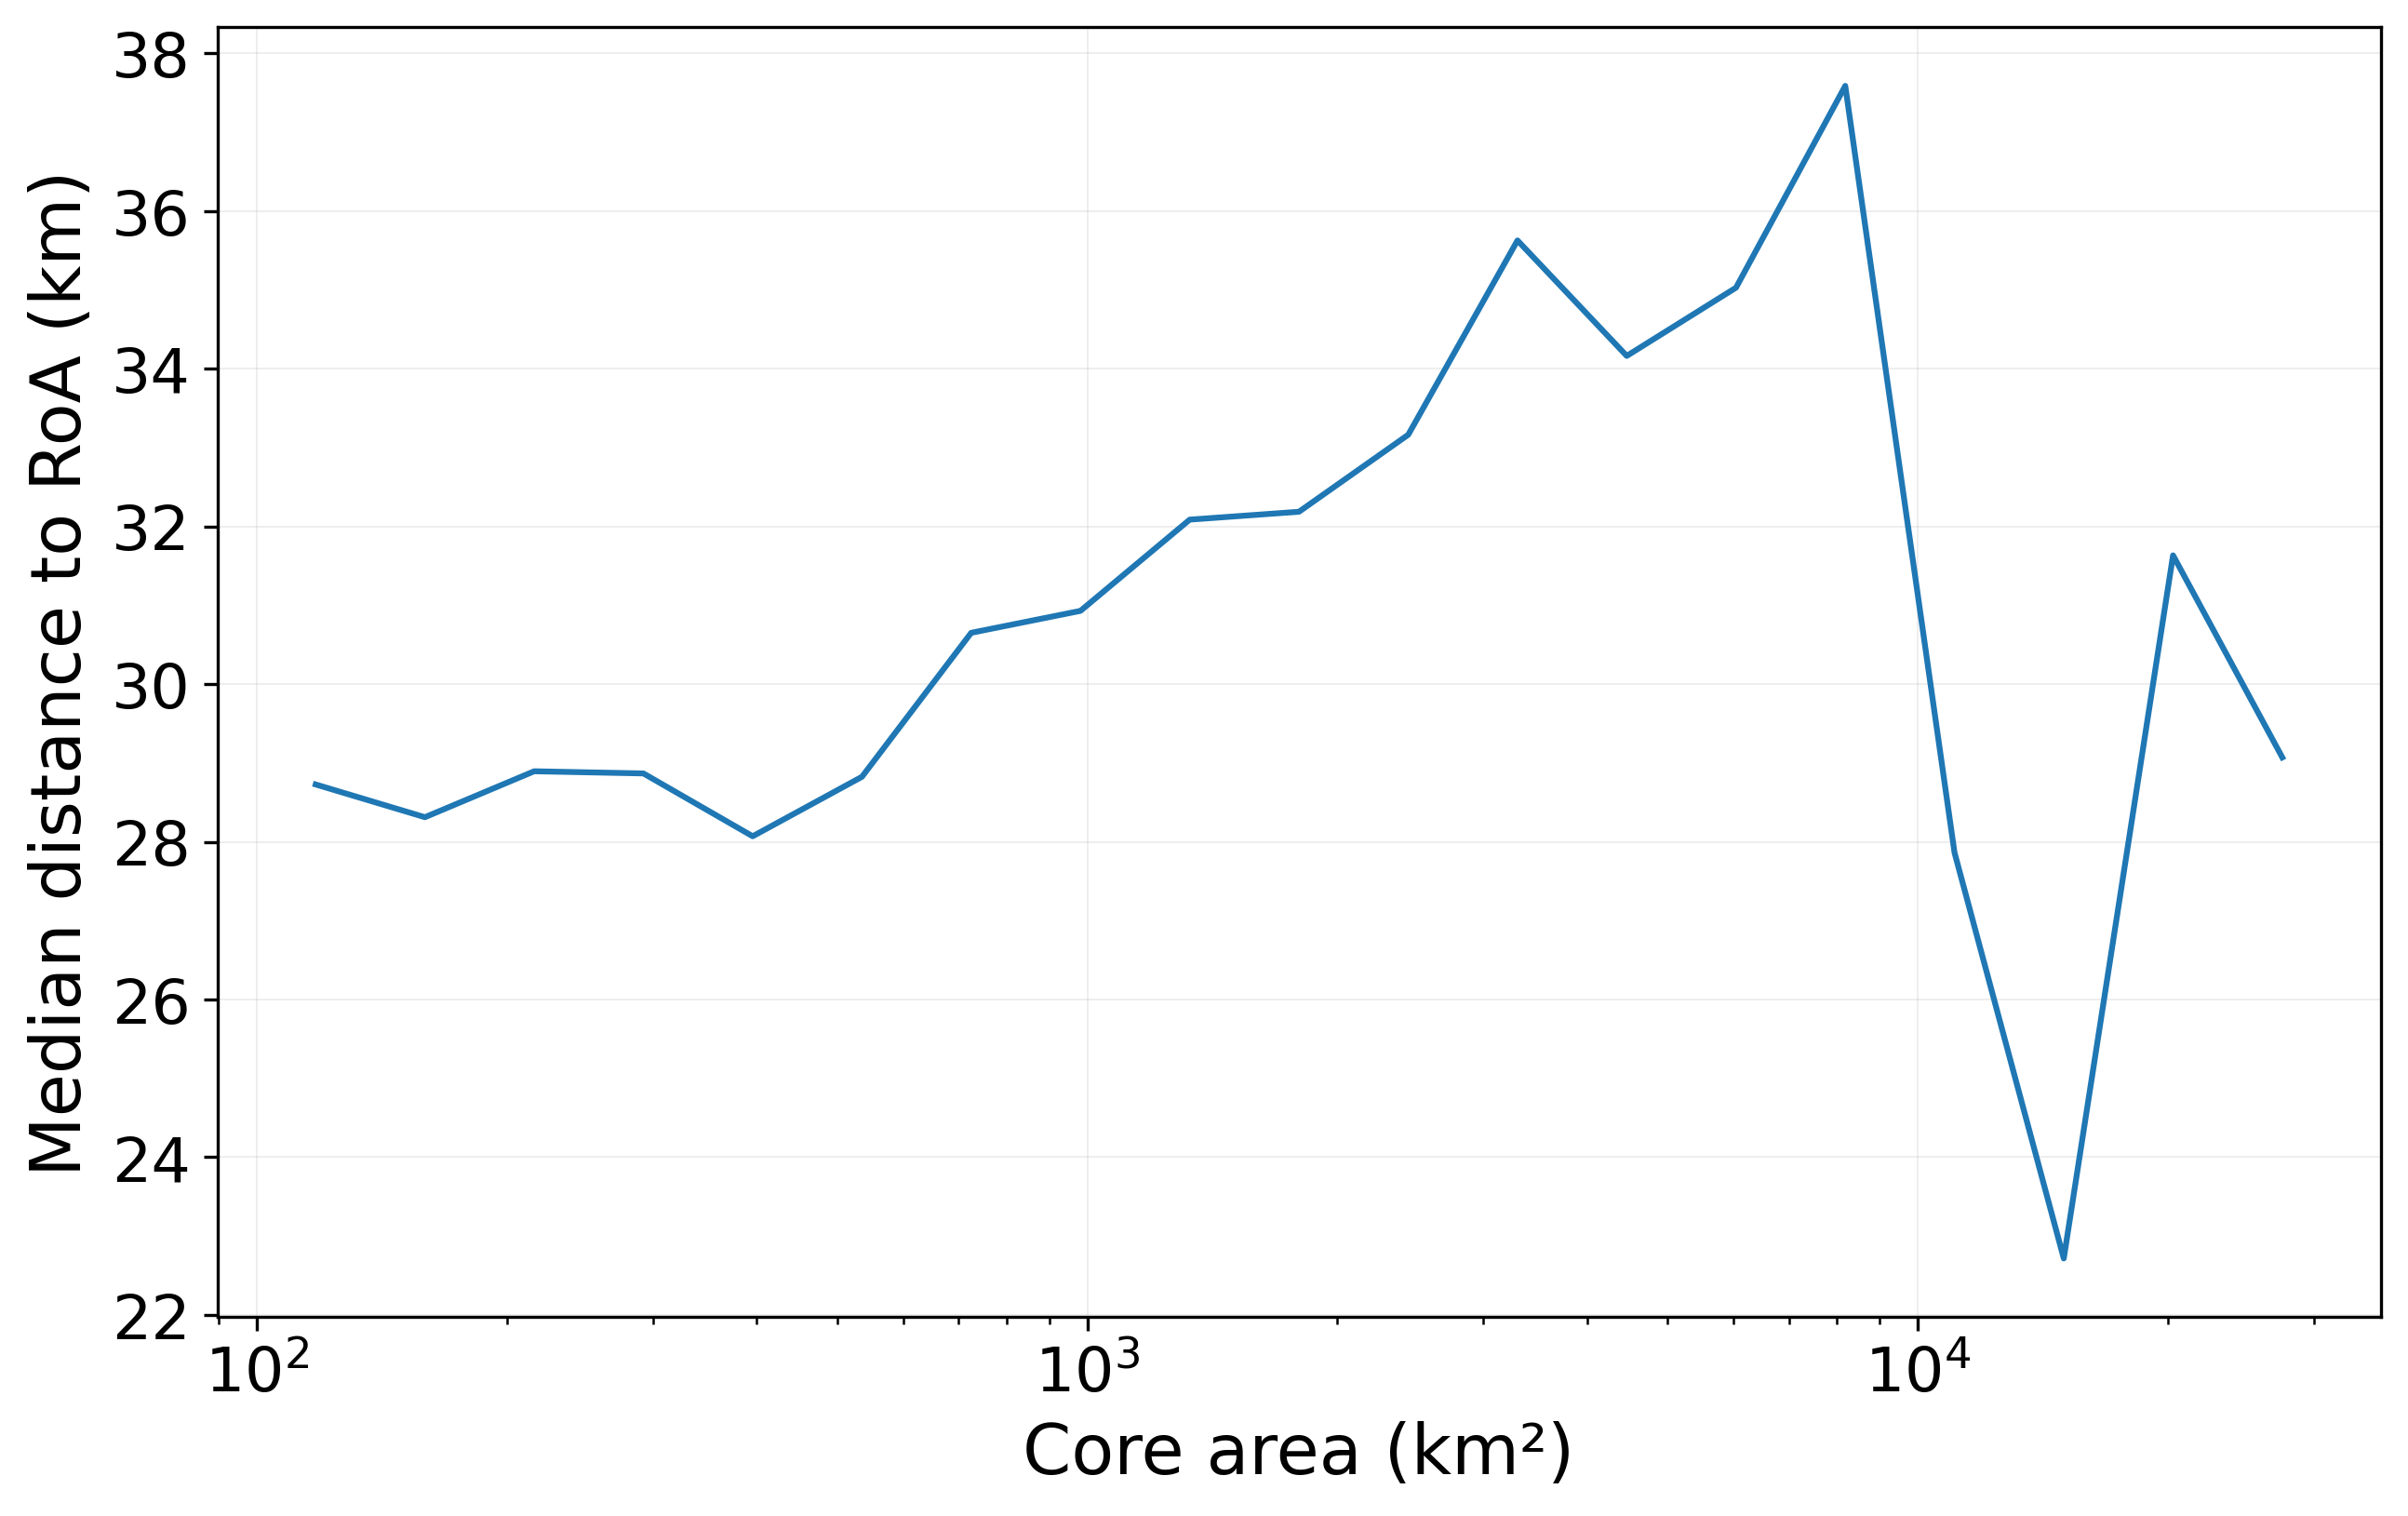

In [19]:
bins = np.logspace(2, 4.5, 20)
df_temp = df_core_90.copy()
df_temp["dist"] = core_roa_90

df_temp["bin"] = pd.cut(df_temp["size"], bins)

median_dist = df_temp.groupby("bin")["dist"].median()
bin_centres = [b.mid for b in median_dist.index]

plt.figure(figsize=(10,6), dpi=300)
plt.plot(bin_centres, median_dist)

plt.xscale("log")

plt.xlabel("Core area (km²)", fontsize=18)
plt.ylabel("Median distance to RoA (km)", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True, linewidth=0.1)
plt.show()

In [3]:
import numpy as np
from scipy.spatial import cKDTree

In [4]:
def latlon_to_xy_km(lat, lon):
    R = 6371.0
    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)
    x = R * lon_rad * np.cos(np.mean(lat_rad))
    y = R * lat_rad
    return np.column_stack((x, y))

In [5]:
def nearest_distances(df_a, df_b):
    
    time_cols = ["year", "month", "day", "hour"]
    distances_all = []

    for time_key, group_a in df_a.groupby(time_cols):

        group_b = df_b[
            (df_b["year"]  == time_key[0]) &
            (df_b["month"] == time_key[1]) &
            (df_b["day"]   == time_key[2]) &
            (df_b["hour"]  == time_key[3])
        ]

        if len(group_a) == 0 or len(group_b) == 0:
            continue

        xy_b = latlon_to_xy_km(
            group_b["lat_centroid"].values,
            group_b["lon_centroid"].values
        )

        tree = cKDTree(xy_b)

        xy_a = latlon_to_xy_km(
            group_a["lat_centroid"].values,
            group_a["lon_centroid"].values
        )

        dists, _ = tree.query(xy_a, k=1)
        distances_all.extend(dists)

    return np.array(distances_all)


In [6]:
# Core → RoA
core_roa_90 = nearest_distances(df_core_90, df_roa_90)

# RoA → Core
roa_core_90 = nearest_distances(df_roa_90, df_core_90)

In [10]:
# Core → RoA (95th)
core_roa_95 = nearest_distances(df_core_95, df_roa_95)

# RoA → Core (95th)
roa_core_95 = nearest_distances(df_roa_95, df_core_95)

In [7]:
print("Core → RoA")
print("Median:", np.median(core_roa_90))
print("50 km match rate:", np.mean(core_roa_90 <= 50))
print("100 km match rate:", np.mean(core_roa_90 <= 100))

print("\nRoA → Core")
print("Median:", np.median(roa_core_90))
print("50 km match rate:", np.mean(roa_core_90 <= 50))
print("100 km match rate:", np.mean(roa_core_90 <= 100))

Core → RoA
Median: 30.176886325616614
50 km match rate: 0.6825050091143283
100 km match rate: 0.9151990840476657

RoA → Core
Median: 443.10672766400677
50 km match rate: 0.04662054222613704
100 km match rate: 0.10363824784980413


In [11]:
print("95th Percentile")

print("Core → RoA")
print("Median:", np.median(core_roa_95))
print("50 km match rate:", np.mean(core_roa_95 <= 50))
print("100 km match rate:", np.mean(core_roa_95 <= 100))

print("\nRoA → Core")
print("Median:", np.median(roa_core_95))
print("50 km match rate:", np.mean(roa_core_95 <= 50))
print("100 km match rate:", np.mean(roa_core_95 <= 100))

95th Percentile
Core → RoA
Median: 20.449099019923537
50 km match rate: 0.8195714589536367
100 km match rate: 0.9619310931518503

RoA → Core
Median: 442.036885207168
50 km match rate: 0.05894745240000698
100 km match rate: 0.11935587617145721


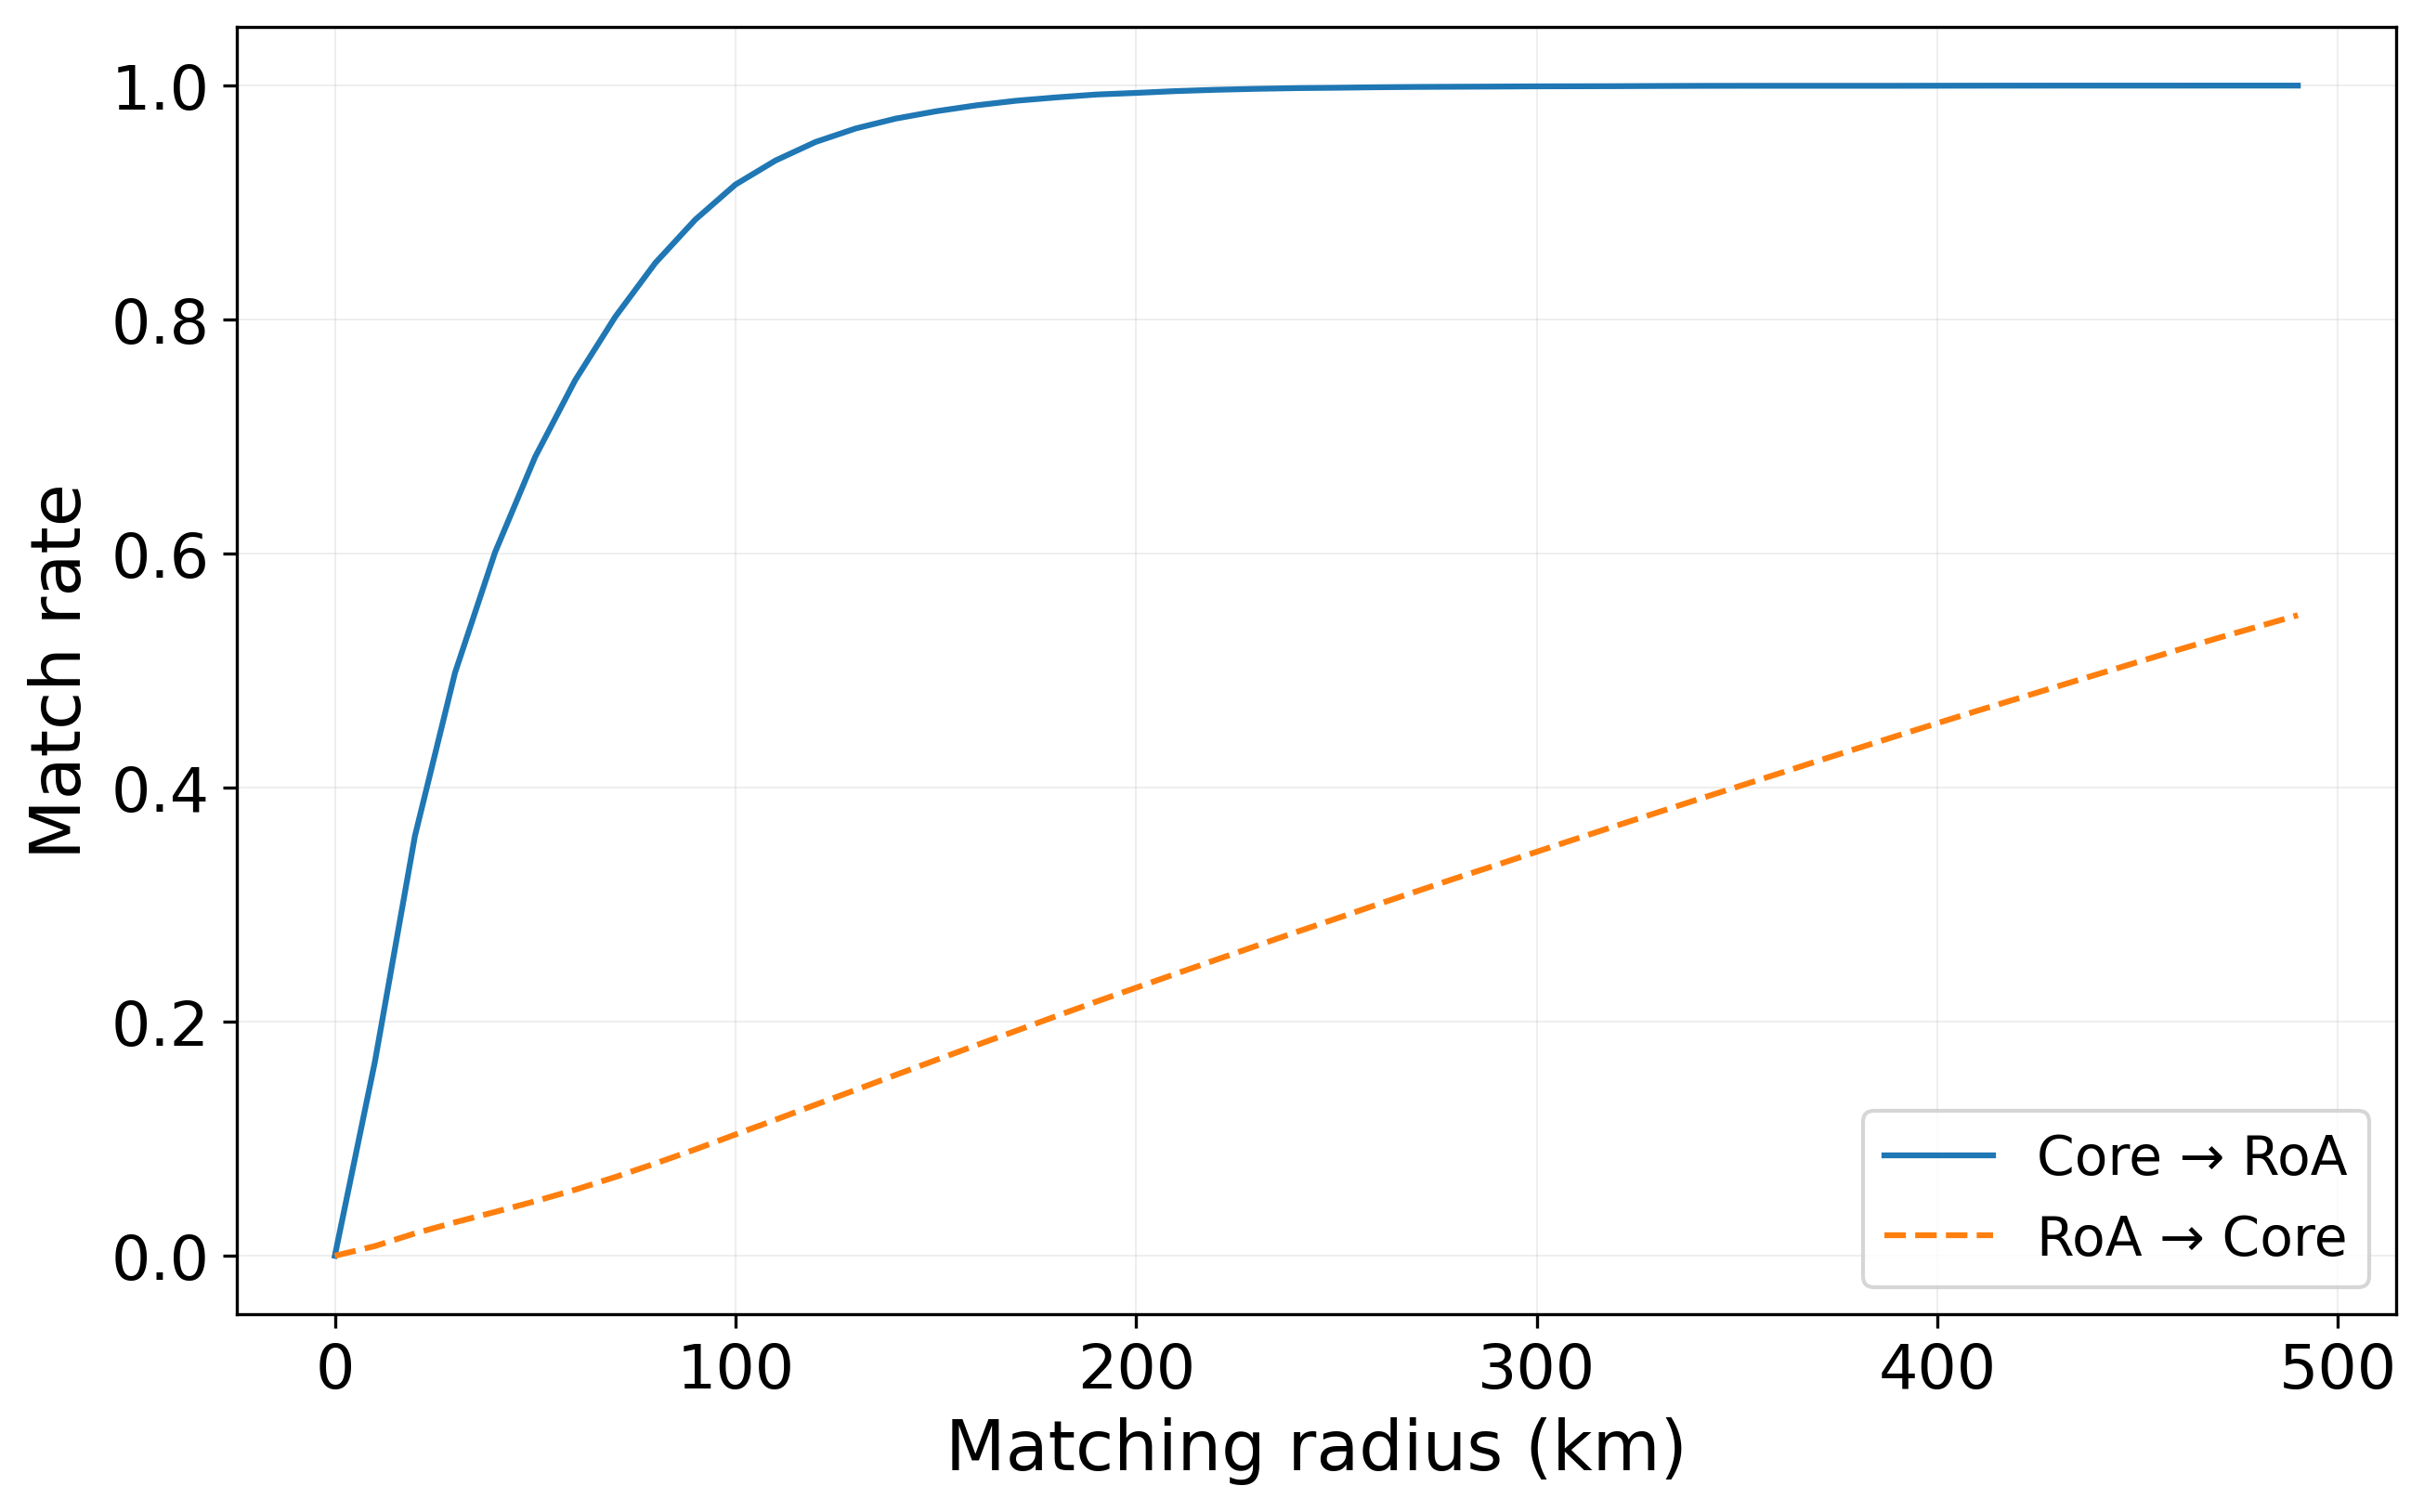

In [9]:
radii = np.arange(0, 500, 10)

rates_core_roa = [np.mean(core_roa_90 <= r) for r in radii]
rates_roa_core = [np.mean(roa_core_90 <= r) for r in radii]

plt.figure(figsize=(10, 6), dpi=300)

plt.plot(radii, rates_core_roa, label="Core → RoA")
plt.plot(radii, rates_roa_core, linestyle="--", label="RoA → Core")

plt.xlabel("Matching radius (km)", fontsize=18)
plt.ylabel("Match rate", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linewidth=0.1)

plt.show()


In [20]:
df_temp = df_core_90.copy()
df_temp = df_temp.iloc[:len(core_roa_90)].copy()
df_temp["dist"] = core_roa_90

In [26]:
df_temp_95 = df_core_95.copy()
df_temp_95 = df_temp_95.iloc[:len(core_roa_95)].copy()
df_temp_95["dist"] = core_roa_95

In [21]:
bins = np.logspace(2, 4.5, 15)  # adjust range if needed
df_temp["size_bin"] = pd.cut(df_temp["size"], bins)


In [27]:
bins = np.logspace(2, 4.5, 15)
df_temp_95["size_bin"] = pd.cut(df_temp_95["size"], bins)

In [22]:
prob_50 = (
    df_temp
    .groupby("size_bin")["dist"]
    .apply(lambda x: np.mean(x <= 50))
)

bin_centres = [b.mid for b in prob_50.index]

/tmp/ipykernel_573630/2193092344.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("size_bin")["dist"]


In [28]:
prob_50_95 = (
    df_temp_95
    .groupby("size_bin")["dist"]
    .apply(lambda x: np.mean(x <= 50))
)

counts_95 = df_temp_95.groupby("size_bin")["dist"].count()

/tmp/ipykernel_573630/3828710865.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("size_bin")["dist"]
/tmp/ipykernel_573630/3828710865.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts_95 = df_temp_95.groupby("size_bin")["dist"].count()


In [29]:
min_count = 100
valid_bins_95 = counts_95[counts_95 >= min_count].index

prob_50_95_clean = prob_50_95[valid_bins_95]
bin_centres_95 = [b.mid for b in prob_50_95_clean.index]

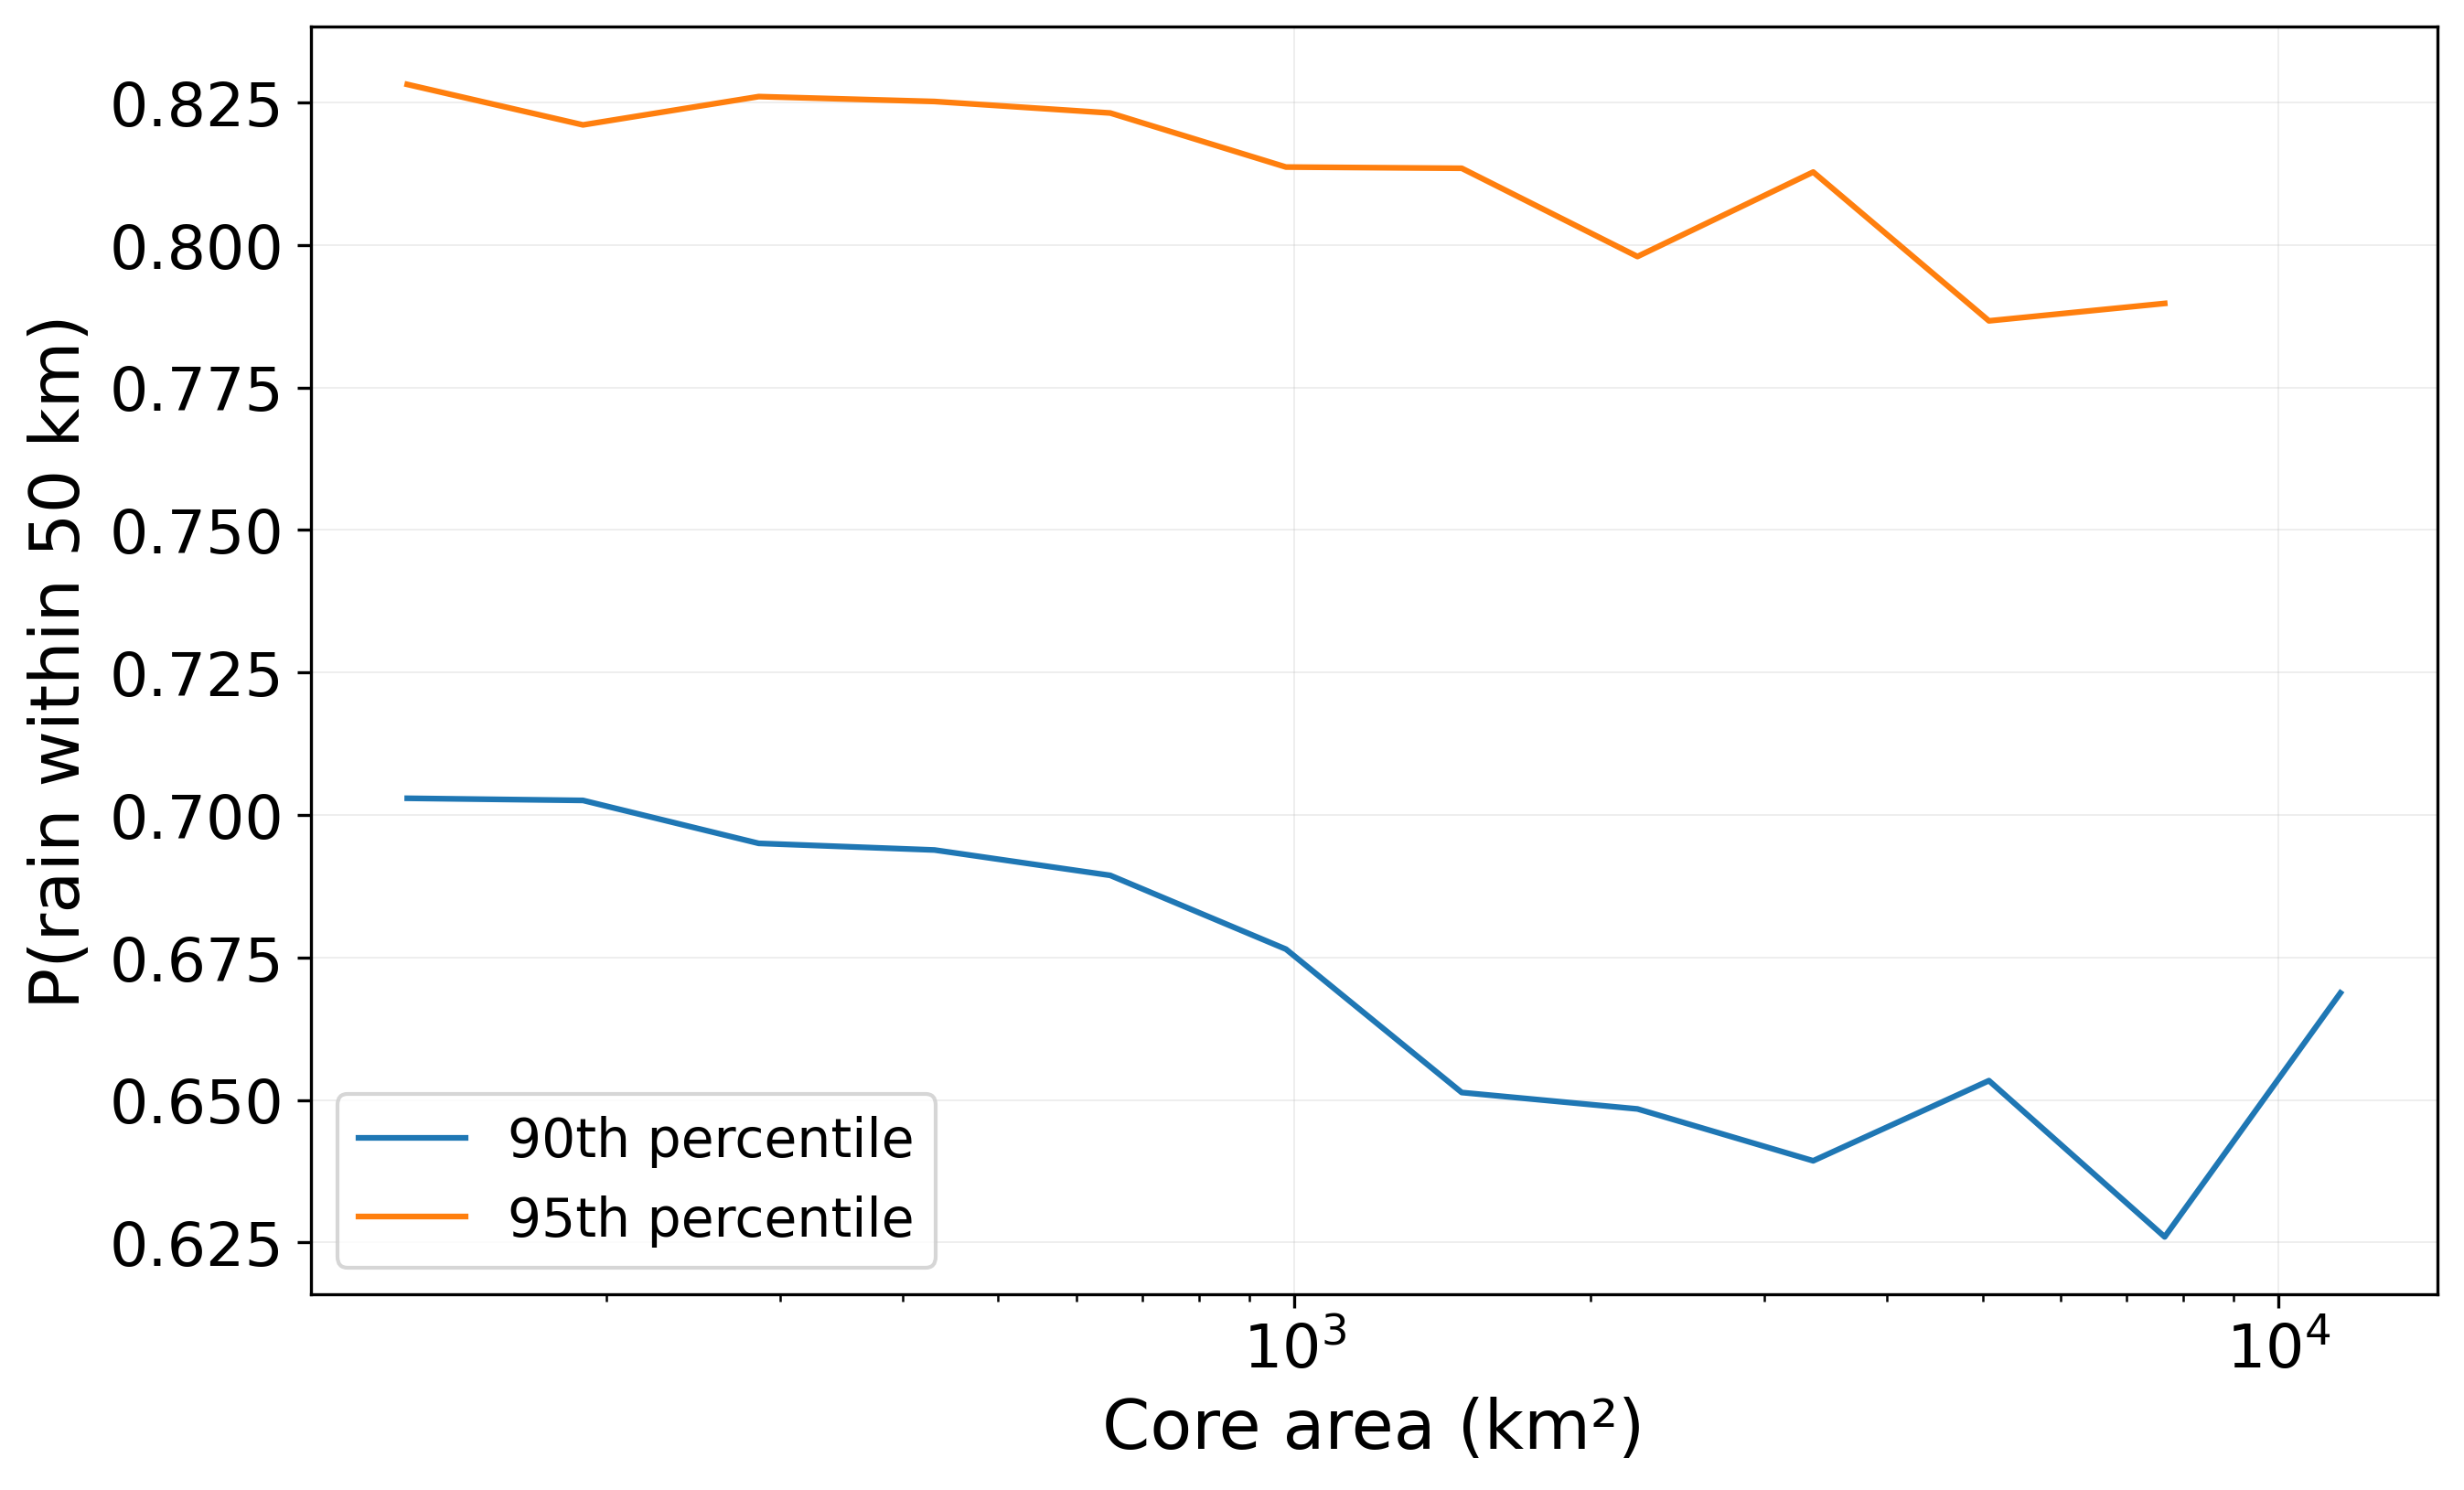

In [30]:
plt.figure(figsize=(10, 6), dpi=300)

plt.plot(bin_centres_clean, prob_50_clean, label="90th percentile")
plt.plot(bin_centres_95, prob_50_95_clean, label="95th percentile")

plt.xscale("log")

plt.xlabel("Core area (km²)", fontsize=18)
plt.ylabel("P(rain within 50 km)", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)
plt.grid(True, linewidth=0.1)

plt.show()

In [24]:
counts = df_temp.groupby("size_bin")["dist"].count()
print(counts)

size_bin
(100.0, 150.859]         8005
(150.859, 227.585]       8664
(227.585, 343.332]       8427
(343.332, 517.947]       8003
(517.947, 781.371]       7605
(781.371, 1178.769]      6837
(1178.769, 1778.279]     5888
(1778.279, 2682.696]     4810
(2682.696, 4047.09]      3416
(4047.09, 6105.402]      2086
(6105.402, 9210.553]      877
(9210.553, 13894.955]     157
(13894.955, 20961.8]       25
(20961.8, 31622.777]        4
Name: dist, dtype: int64


/tmp/ipykernel_573630/3799575045.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = df_temp.groupby("size_bin")["dist"].count()


In [34]:
from scipy.spatial import cKDTree
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

def match_core_to_roa_intensity(df_core, df_roa):

    matched_core_intensity = []
    matched_rain_intensity = []

    for t in df_core["time"].unique():

        core_t = df_core[df_core["time"] == t]
        roa_t  = df_roa[df_roa["time"] == t]

        if len(core_t) == 0 or len(roa_t) == 0:
            continue

        tree = cKDTree(
            np.column_stack([
                roa_t["lat_centroid"].values,
                roa_t["lon_centroid"].values
            ])
        )

        core_points = np.column_stack([
            core_t["lat_centroid"].values,
            core_t["lon_centroid"].values
        ])

        dist, idx = tree.query(core_points)

        matched_core_intensity.extend(core_t["mean_core"].values)
        matched_rain_intensity.extend(roa_t.iloc[idx]["mean_roa"].values)

    return np.array(matched_core_intensity), np.array(matched_rain_intensity)

In [35]:
core_wp_90, rain_int_90 = match_core_to_roa_intensity(df_core_90, df_roa_90)

rho_90, pval_90 = spearmanr(core_wp_90, rain_int_90)

print("Spearman ρ (90th):", rho_90)
print("p-value:", pval_90)

Spearman ρ (90th): 0.09933893775352032
p-value: 3.549980781473024e-145


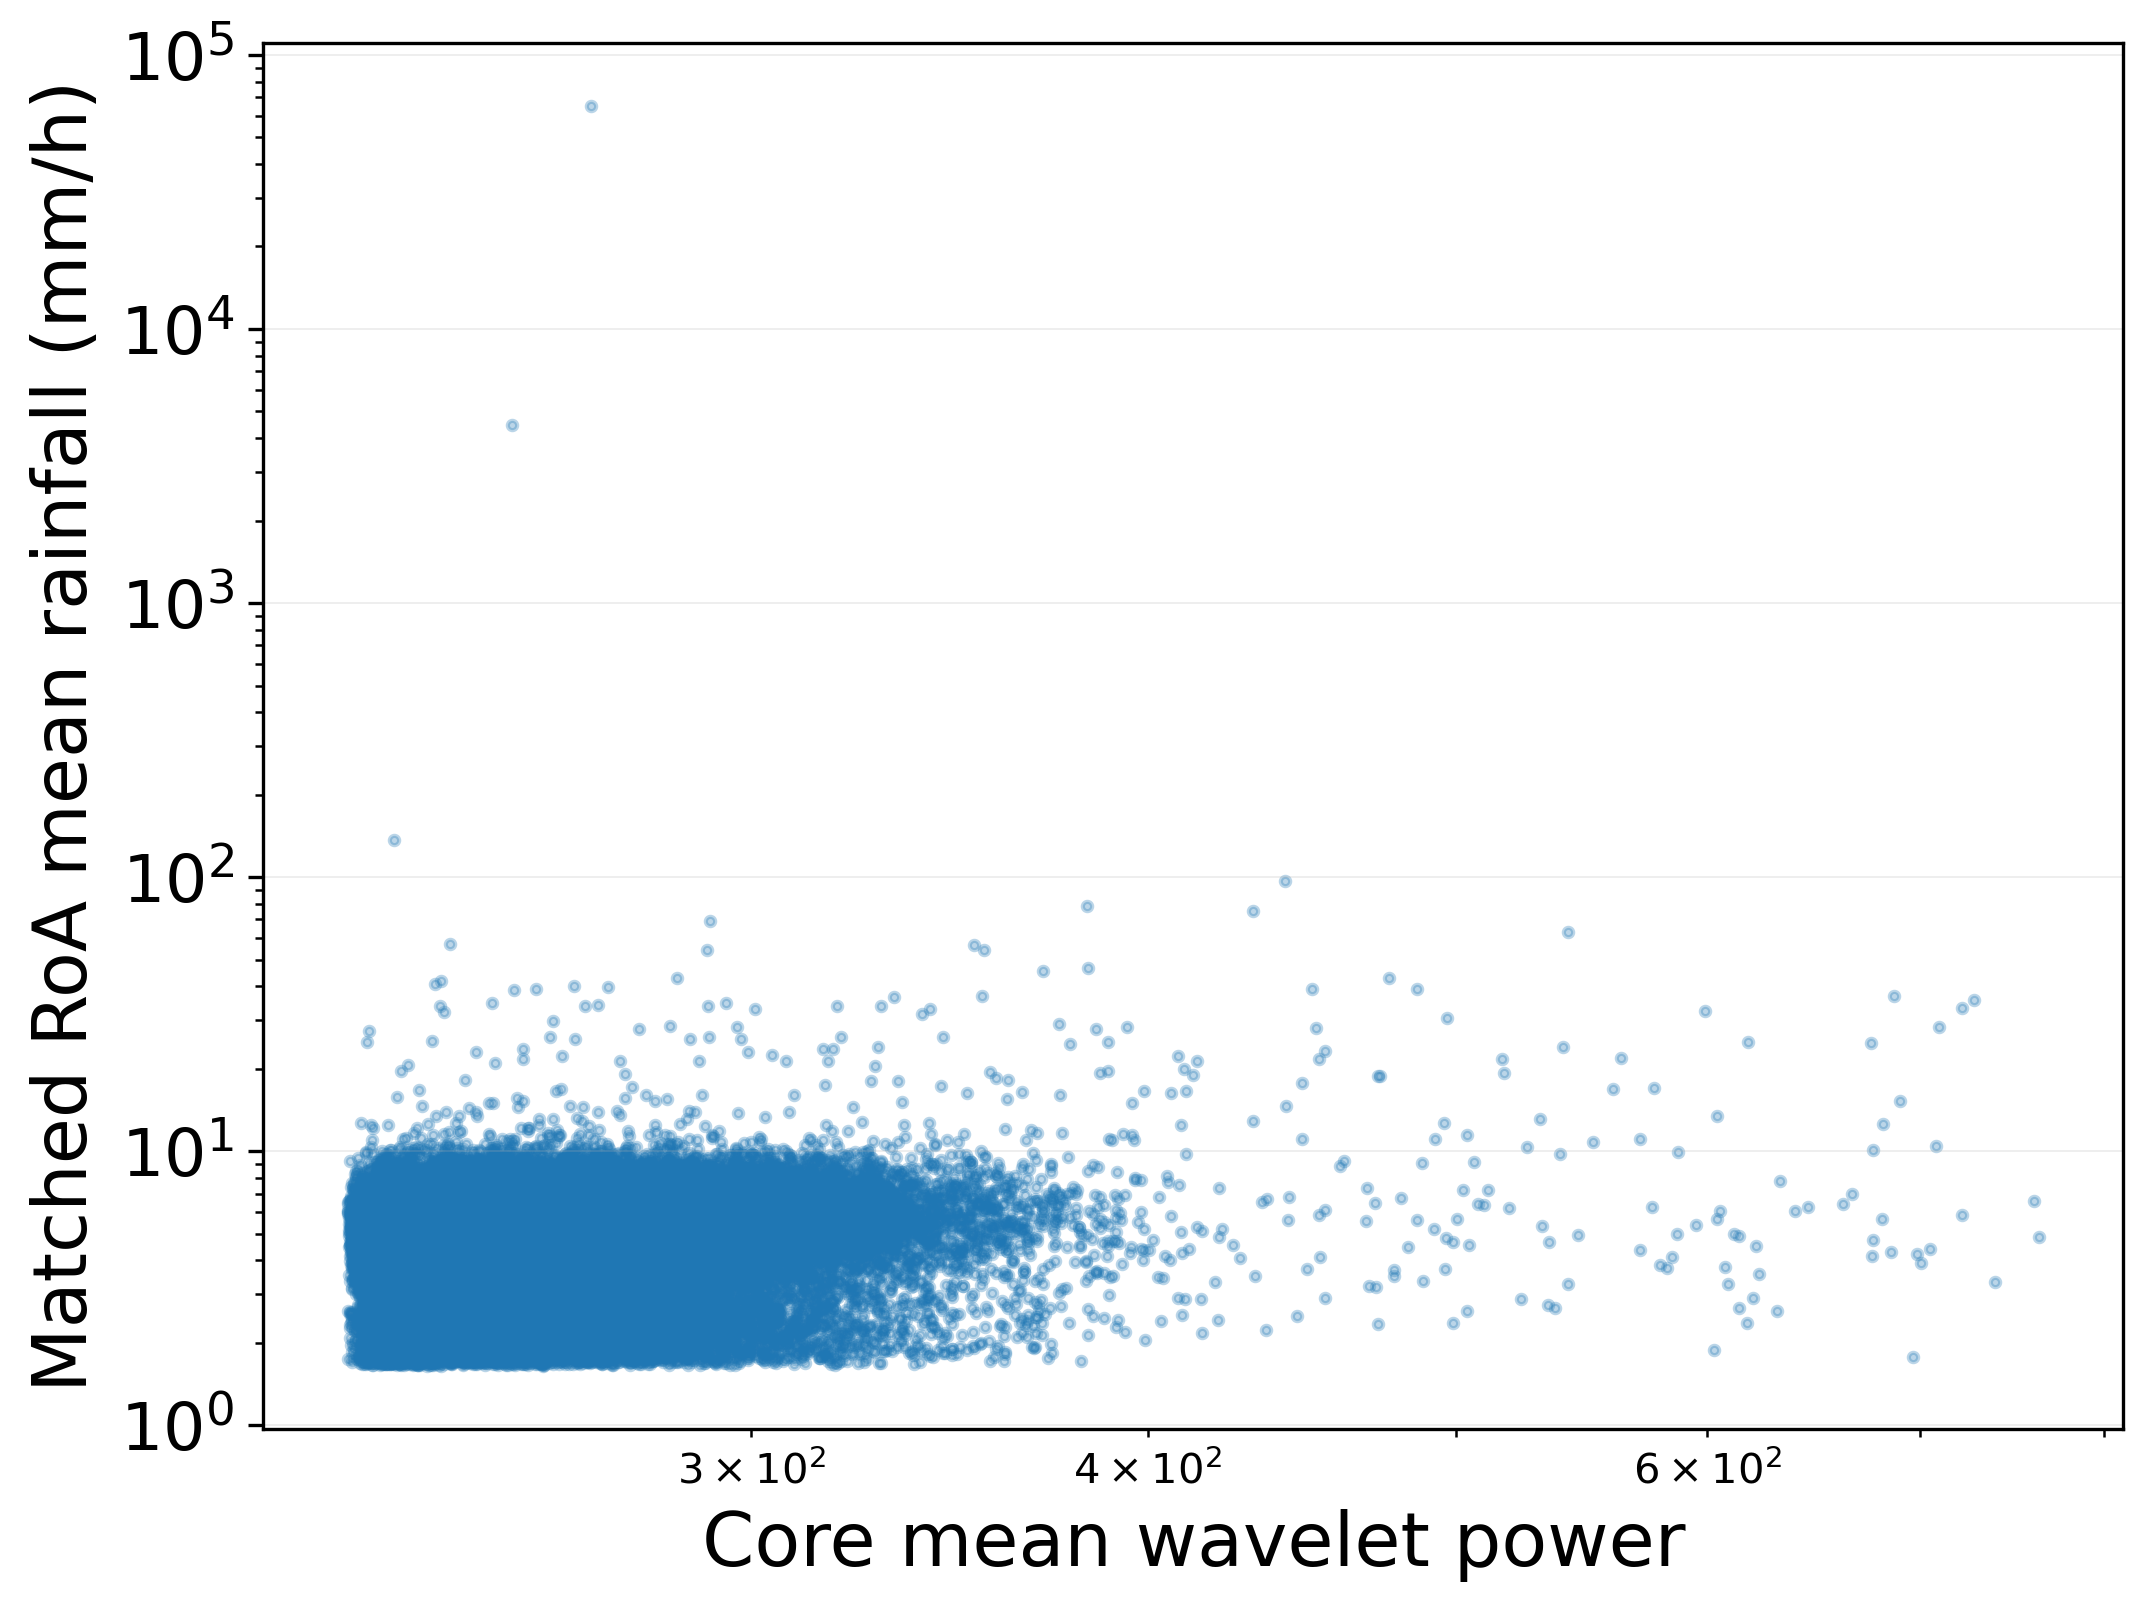

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6), dpi=300)

plt.scatter(core_wp_90, rain_int_90, s=5, alpha=0.3)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Core mean wavelet power", fontsize=18)
plt.ylabel("Matched RoA mean rainfall (mm/h)", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True, linewidth=0.1)

plt.show()


Spearman rho: 0.018747192199841466


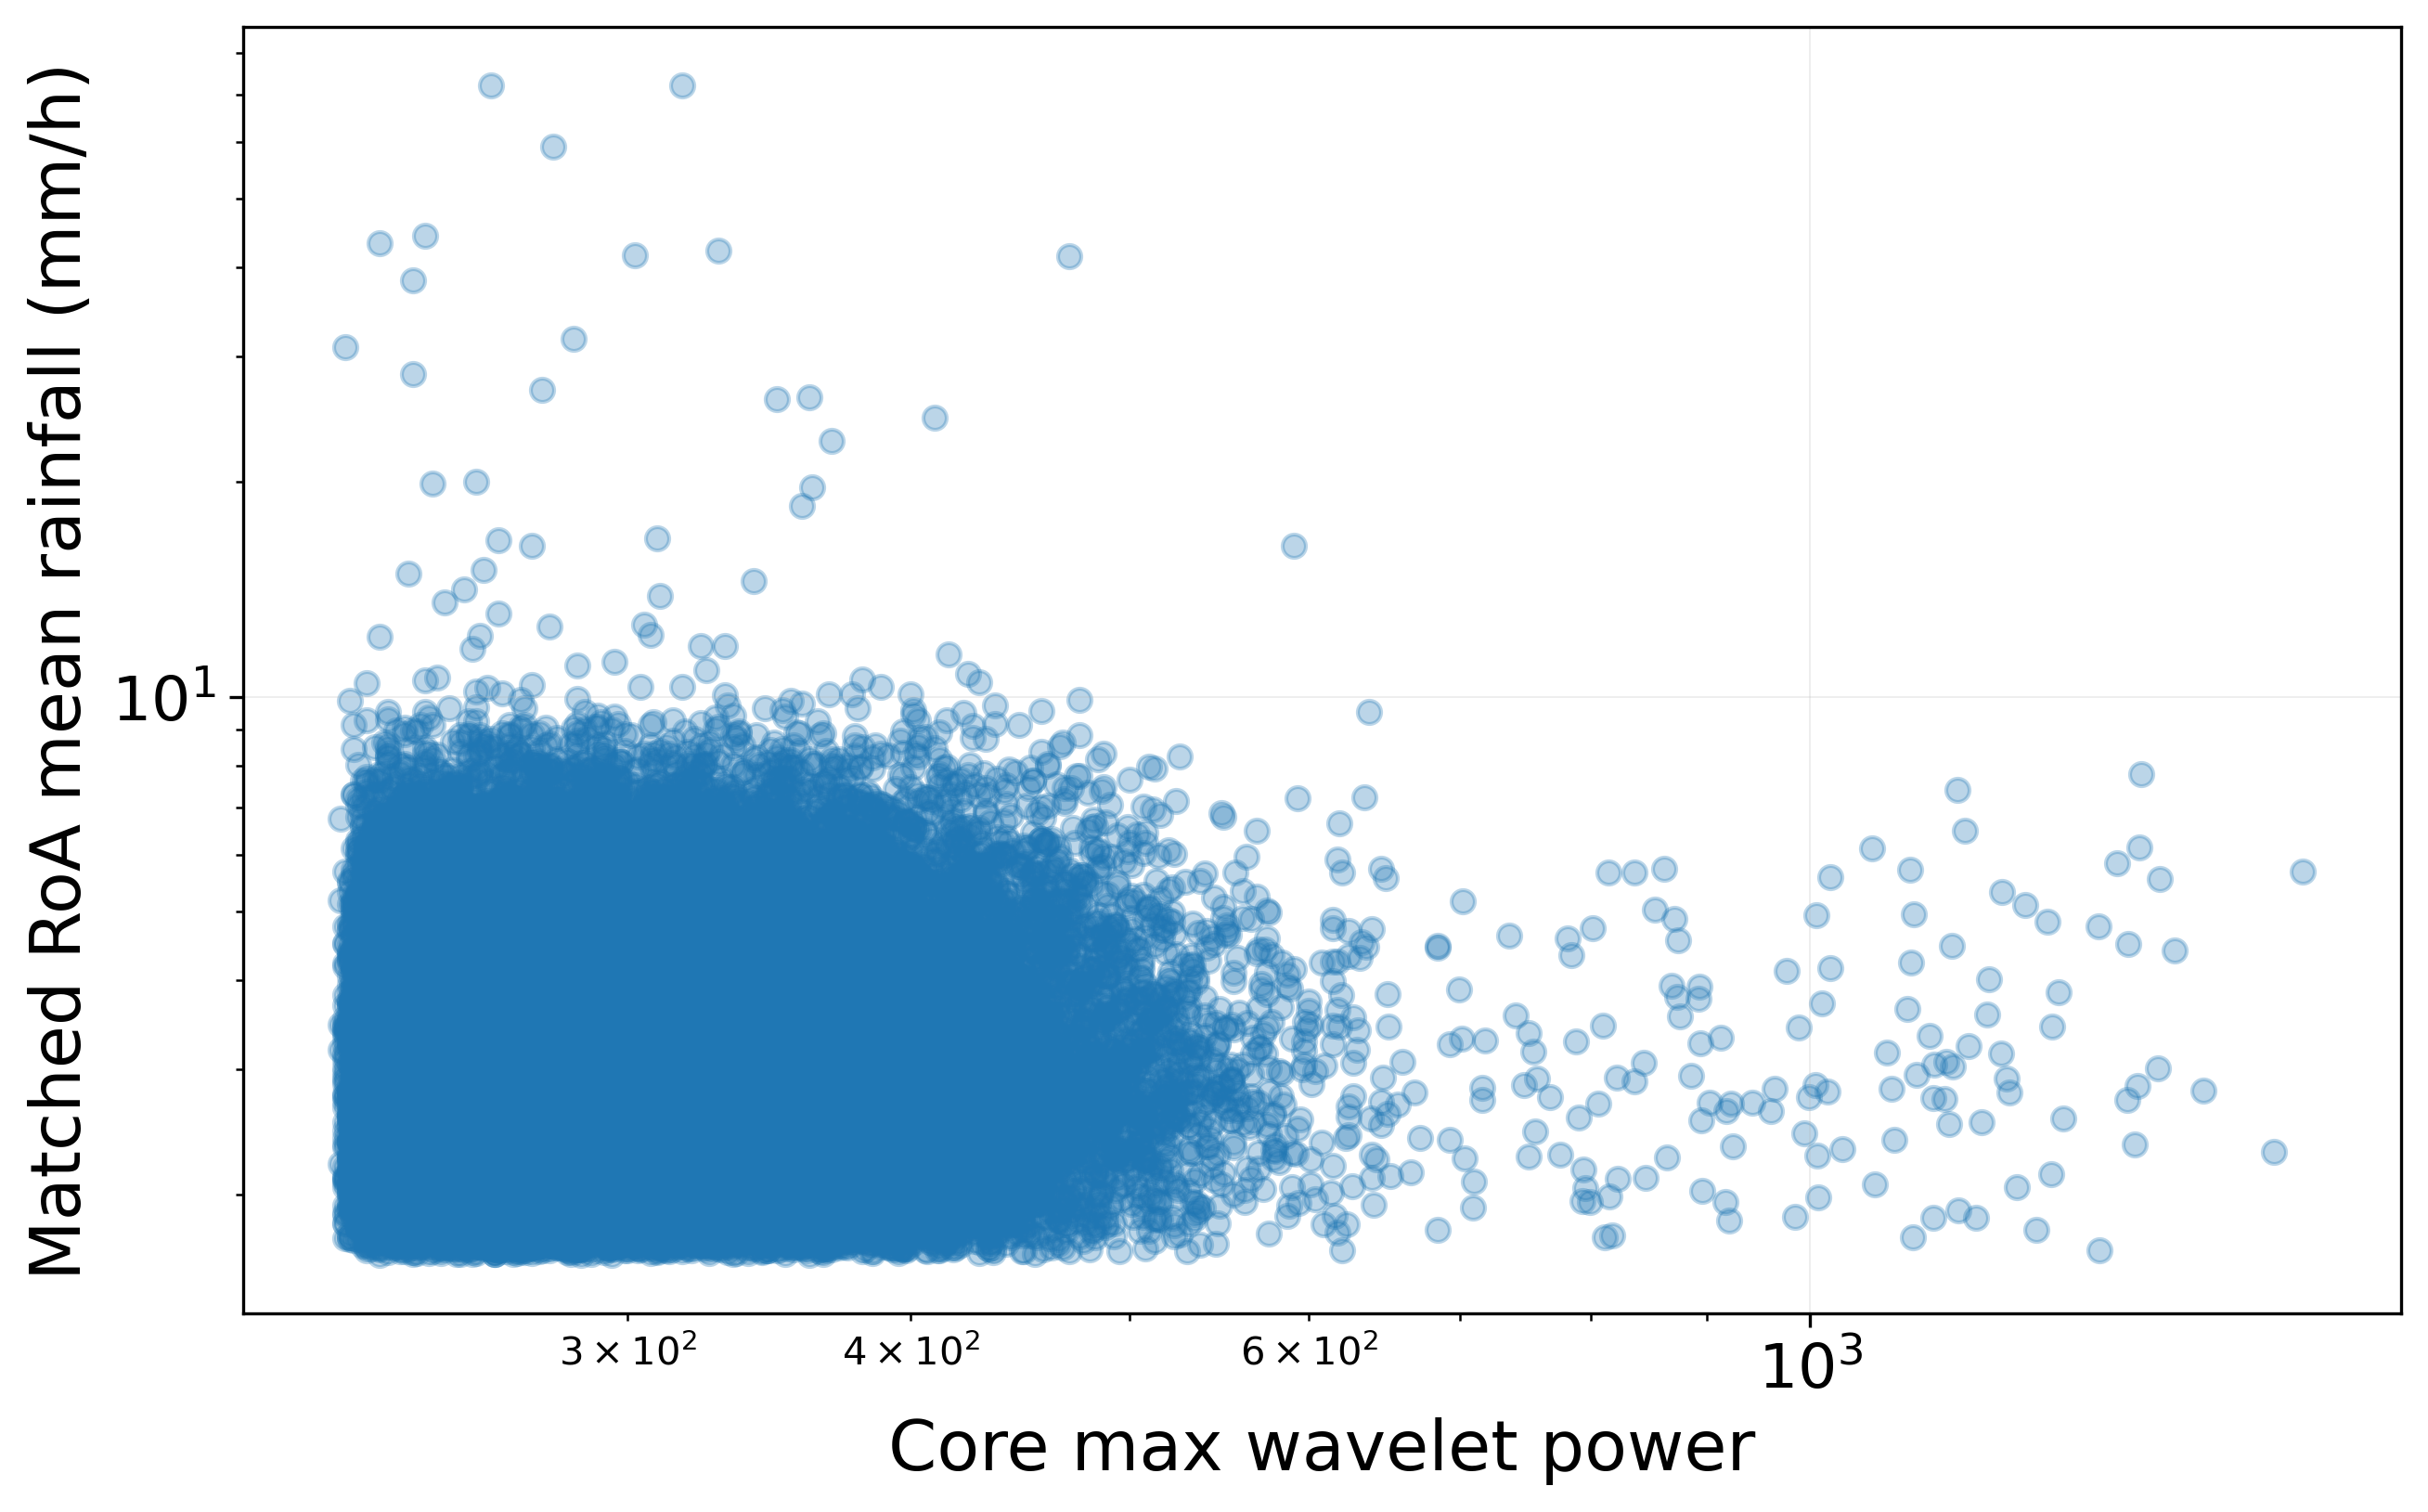

In [47]:
from scipy.spatial import cKDTree
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Build KDTree for RoA
coords_roa = np.column_stack([
    df_roa_90["lat_centroid"],
    df_roa_90["lon_centroid"]
])

tree = cKDTree(coords_roa)

coords_core = np.column_stack([
    df_core_90["lat_centroid"],
    df_core_90["lon_centroid"]
])

dist, idx = tree.query(coords_core, k=1)

# Extract variables
core_max_wp = df_core_90["max_core"].values
matched_rain_mean = df_roa_90["mean_roa"].values[idx]

# Remove extreme rainfall outliers if needed
mask = matched_rain_mean < 200
core_max_wp = core_max_wp[mask]
matched_rain_mean = matched_rain_mean[mask]

# Spearman correlation
rho, p = spearmanr(core_max_wp, matched_rain_mean)
print("Spearman rho:", rho)

# Plot
plt.figure(figsize=(10, 6), dpi=300)

plt.scatter(core_max_wp, matched_rain_mean, alpha=0.3)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Core max wavelet power", fontsize=18)
plt.ylabel("Matched RoA mean rainfall (mm/h)", fontsize=18)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True, linewidth=0.1)

plt.show()